# 10.2 Caries full-image audit

Executed existing-weight CPU inference, fixed stress tests and annotation-relative error analysis.

```mermaid
flowchart LR
    A[Locked validation inputs] --> B[Verify identities and processing]
    B --> C[Recompute metrics and inspect errors]
    C --> D[Save evidence and decide next experiment]
```

## 1. Runtime, scope and fixed protocol
Reuse existing weights. Evaluate full validation photographs at 640 input. CPU timing is a desktop measurement, not phone performance. Corruptions are fixed synthetic stress tests, not real phone-photo validation.

In [1]:
from pathlib import Path
import hashlib, json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageEnhance
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/dentalselfie').exists(), 'Run from project root or notebooks directory'
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2), encoding='utf-8')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Root:', ROOT, '| Python:', platform.python_version())

import os, io, shutil, yaml, torch, ultralytics
os.environ['YOLO_AUTOINSTALL']='false'
from ultralytics import YOLO
torch.set_num_threads(min(8,os.cpu_count() or 1))
OUT=ROOT/'docs/reports/post09/caries';OUT.mkdir(parents=True,exist_ok=True)
WORK=ROOT/'.venv/work/audit10/caries';WORK.mkdir(parents=True,exist_ok=True)
assert ultralytics.__version__=='8.4.183'
protocol={'imgsz':640,'batch':8,'workers':0,'device':'cpu','conf':0.001,'iou':0.7,
          'max_det':300,'half':False,'augment':False,'split':'val',
          'diagnostic_confidence':0.25,'diagnostic_iou':0.5,
          'variants':['clean','blur_r1_5','dark_0_65','jpeg_q35']}
display(pd.Series(protocol).to_frame('fixed setting'))
print('Torch',torch.__version__,'Ultralytics',ultralytics.__version__)

Root: C:\Users\huynh\Desktop\oral-disease | Python: 3.11.15


,fixed setting
imgsz,640
batch,8
workers,0
device,cpu
conf,0.001
iou,0.7
max_det,300
half,False
augment,False
split,val


Torch 2.11.0+cpu Ultralytics 8.4.183


## 2. Lock validation membership and verify input bytes
Read the split table, then open only validation image/label paths. Missing annotations remain an uncertainty, not healthy negatives.

In [2]:
lock=json.loads((ROOT/'data/manifests/caries.lock.json').read_text())
assert sha(ROOT/'data/manifests/caries.splits.csv')==lock['splits_sha256']
manifest=pd.read_csv(ROOT/'data/manifests/caries.splits.csv')
val=manifest[manifest.split.eq('val')].copy()
assert len(val)==327 and val.sample_id.is_unique
gt={}; labels=[]
for row in val.itertuples():
    assert sha(ROOT/row.image)==row.sha256 and sha(ROOT/row.label)==row.label_sha256
    boxes=[]
    for line in (ROOT/row.label).read_text().splitlines():
        cls,cx,cy,w,h=map(float,line.split());assert cls==0 and w>0 and h>0
        box=[(cx-w/2)*row.width,(cy-h/2)*row.height,(cx+w/2)*row.width,(cy+h/2)*row.height]
        boxes.append(box)
        area=(w*row.width)*(h*row.height)*(640/max(row.width,row.height))**2
        labels.append({'sample_id':row.sample_id,'gt_index':len(boxes)-1,'area_640':area,
                       'size':'small' if area<32**2 else ('medium' if area<96**2 else 'large')})
    gt[row.sample_id]=boxes
lesions=pd.DataFrame(labels);lesions.to_csv(OUT/'lesion_size_membership.csv',index=False)
display(val.groupby(['source_collection','view']).agg(images=('sample_id','size'),boxes=('label_count','sum')))
display(lesions.groupby('size').size().rename('lesions').to_frame())
print('Size bins use box area after isotropic scaling to maximum edge 640: <32^2, <96^2, otherwise large.')

images  boxes
source_collection view                             
no_retractors     Left_Lateral             5      5
                  Mandibular              78    283
                  Maxillary_Occlusal      59    180
                  Right_Lateral            3      3
pilot             Frontal                  1      1
                  Left_Lateral             2      1
                  Mandibular              20     68
                  Maxillary_Occlusal      12     29
retractors        Frontal                  2      3
                  Left_Lateral             5      7
                  Mandibular              74    268
                  Maxillary_Occlusal      59    199
                  Right_Lateral            7      7

,lesions
size,
large,443
medium,611


Size bins use box area after isotropic scaling to maximum edge 640: <32^2, <96^2, otherwise large.


## 3. Deterministic complete-image stress inputs
Transform the full photograph before model resizing. Keep box coordinates and image dimensions fixed. JPEG q35 uses one re-encode from the prepared image; blur/dark variants use high-quality PNG to avoid extra JPEG confounding.

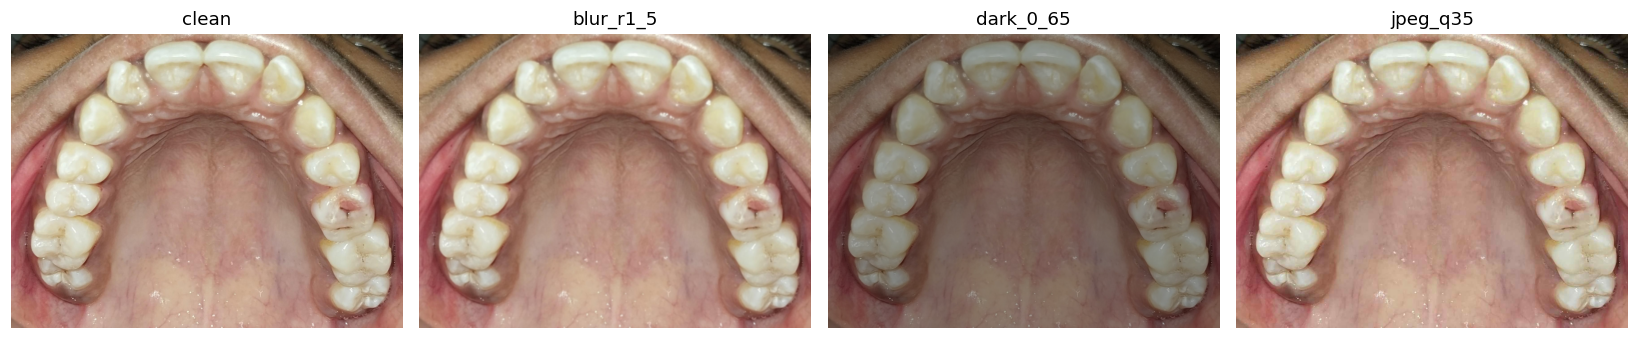

Prepared all four fixed validation variants: 327 images each


In [3]:
variant_paths={}
for variant in protocol['variants']:
    paths=[]
    for row in val.itertuples():
        if variant=='clean':
            path=ROOT/row.image
        else:
            folder=WORK/variant
            extension='.jpg' if variant=='jpeg_q35' else '.png'
            path=folder/'images'/(row.sample_id+extension)
            path.parent.mkdir(parents=True,exist_ok=True)
            label=folder/'labels'/(row.sample_id+'.txt');label.parent.mkdir(parents=True,exist_ok=True)
            if not path.exists():
                with Image.open(ROOT/row.image) as opened:
                    image=opened.convert('RGB')
                    if variant=='blur_r1_5':image=image.filter(ImageFilter.GaussianBlur(1.5))
                    if variant=='dark_0_65':image=ImageEnhance.Brightness(image).enhance(.65)
                    if variant=='jpeg_q35':image.save(path,quality=35,subsampling=2)
                    else:image.save(path)
            shutil.copyfile(ROOT/row.label,label)
            with Image.open(path) as image:assert image.size==(row.width,row.height)
        paths.append(str(path.resolve()))
    listing=WORK/(variant+'.txt');listing.write_text('\n'.join(paths)+'\n',encoding='utf-8')
    config=WORK/(variant+'.yaml')
    config.write_text(yaml.safe_dump({'path':str(ROOT),'train':str(listing),'val':str(listing),'names':{0:'visible_caries'}}))
    variant_paths[variant]=config
fig,axes=plt.subplots(1,4,figsize=(15,4))
for ax,(variant,config) in zip(axes,variant_paths.items()):
    path=Path((WORK/(variant+'.txt')).read_text().splitlines()[0])
    with Image.open(path) as image:ax.imshow(image)
    ax.set_title(variant);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'stress_examples.png');plt.show()
print('Prepared all four fixed validation variants:',len(val),'images each')

## 4. Load existing checkpoints and evaluate all full images
The detector's native postprocessing is retained: YOLO26 end-to-end behavior is not forced into YOLOv8 NMS. Save confidence curves, JSON detections and model-native AP metrics. Reuse a completed audit only if its checkpoint/input/protocol/runtime fingerprint matches.

In [4]:
weights={'YOLOv8n':ROOT/'data/runs/E0_full_v4/experiments/E0_caries_seed42/weights/best.pt',
         'YOLO26n':ROOT/'data/runs/E1_full_v4/experiments/E1_caries_seed42/weights/best.pt'}
summaries=[]
for name,weight in weights.items():
    assert weight.exists()
    model=YOLO(str(weight))
    print('Loaded',name,'parameters:',sum(p.numel() for p in model.model.parameters()),flush=True)
    for variant,config in variant_paths.items():
        run=OUT/(name+'_'+variant);receipt=run/'audit_receipt.json'
        identity={'weight_sha256':sha(weight),'splits_sha256':lock['splits_sha256'],
                  'input_files':[{ 'id':r.sample_id,'image_sha256':sha(Path(p)),'label_sha256':r.label_sha256}
                                 for r,p in zip(val.itertuples(),(WORK/(variant+'.txt')).read_text().splitlines())],
                  'protocol':protocol,'variant':variant,'torch':torch.__version__,
                  'ultralytics':ultralytics.__version__}
        fingerprint=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
        if receipt.exists():
            result=json.loads(receipt.read_text());assert result['fingerprint']==fingerprint
            assert sha(run/'predictions.json')==result['predictions_sha256']
            print('Reused verified audit',name,variant,flush=True)
        else:
            start=time.perf_counter()
            metrics=model.val(data=str(config),imgsz=640,batch=8,workers=0,device='cpu',
                              conf=.001,iou=.7,max_det=300,half=False,augment=False,split='val',
                              save_json=True,plots=True,project=str(OUT),name=run.name,exist_ok=True,verbose=False)
            result={'model':name,'variant':variant,'fingerprint':fingerprint,
                    'map50':float(metrics.box.map50),'map50_95':float(metrics.box.map),
                    'precision_native_curve':float(metrics.box.mp),'recall_native_curve':float(metrics.box.mr),
                    'speed_ms_per_image':{k:float(v) for k,v in metrics.speed.items()},
                    'wall_seconds':time.perf_counter()-start,'test_images_opened':0,
                    'predictions_sha256':sha(run/'predictions.json'),'identity':identity}
            save_json(receipt,result)
        summaries.append({k:v for k,v in result.items() if k not in ['identity','speed_ms_per_image']})
        print(name,variant,'mAP50:',result['map50'],'mAP50-95:',result['map50_95'],flush=True)
summary=pd.DataFrame(summaries);summary.to_csv(OUT/'native_detection_metrics.csv',index=False)
display(summary[['model','variant','map50','map50_95','wall_seconds']])

Loaded YOLOv8n parameters: 3138003


Reused verified audit YOLOv8n clean


YOLOv8n clean mAP50: 0.9354463483887415 mAP50-95: 0.7272728531261734


Reused verified audit YOLOv8n blur_r1_5


YOLOv8n blur_r1_5 mAP50: 0.9345358481126271 mAP50-95: 0.7212643623464245


Reused verified audit YOLOv8n dark_0_65


... (9 outputs left out)

YOLO26n dark_0_65 mAP50: 0.9409421692716745 mAP50-95: 0.7189832701922025


Reused verified audit YOLO26n jpeg_q35


YOLO26n jpeg_q35 mAP50: 0.9390819555260317 mAP50-95: 0.7298154675784191


,model,variant,map50,map50_95,wall_seconds
0,YOLOv8n,clean,0.935446,0.727273,30.996544
1,YOLOv8n,blur_r1_5,0.934536,0.721264,18.483587
2,YOLOv8n,dark_0_65,0.932635,0.721714,22.231170
3,YOLOv8n,jpeg_q35,0.933672,0.722987,13.246664
4,YOLO26n,clean,0.941227,0.730115,14.278723
5,YOLO26n,blur_r1_5,0.937436,0.726929,15.916672
6,YOLO26n,dark_0_65,0.940942,0.718983,19.117611
7,YOLO26n,jpeg_q35,0.939082,0.729815,10.969242


## 5. Auditable one-to-one matching implementation
At confidence >=0.25 and IoU >=0.5, match predictions in descending score order to unmatched GT boxes. Count duplicates separately from localization errors. An unmatched prediction is an apparent annotation-relative false positive; it may need annotation review.

In [5]:
"""Deterministic one-to-one localization diagnostics; no clinical relabeling."""

import numpy as np


def box_iou(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    intersection = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:]) -
                              np.maximum(a[:, None, :2], b[None, :, :2])).prod(2)
    area_a = np.maximum(0, a[:, 2:] - a[:, :2]).prod(1)
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def match_boxes(gt, predicted, scores, threshold=0.5):
    """Confidence-ordered matching; each prediction searches unmatched GT first.

    Non-TP predictions are partitioned into duplicate (IoU >= threshold with
    an already matched GT), localization (0.1 <= best IoU < threshold), and
    unmatched. Unmatched means annotation-relative, not proven healthy tissue.
    """
    gt = np.asarray(gt, float).reshape(-1, 4)
    predicted = np.asarray(predicted, float).reshape(-1, 4)
    scores = np.asarray(scores, float)
    if len(scores) != len(predicted):
        raise ValueError("Score/box count mismatch")
    ious = box_iou(predicted, gt)
    used, events = set(), []
    for i in np.argsort(-scores, kind="stable"):
        candidates = [j for j in range(len(gt)) if j not in used and ious[i, j] >= threshold]
        best = float(ious[i].max()) if len(gt) else 0.0
        if candidates:
            j = max(candidates, key=lambda j: ious[i, j])
            used.add(j)
            kind, overlap = "true_positive", float(ious[i, j])
        else:
            j, overlap = None, best
            kind = "duplicate" if best >= threshold else ("localization" if best >= 0.1 else "unmatched")
        events.append({"prediction_index": int(i), "gt_index": j, "kind": kind,
                       "score": float(scores[i]), "iou": overlap})
    return events, [j for j in range(len(gt)) if j not in used]

print('Matching helpers defined; fixed confidence=0.25, IoU=0.5')

Matching helpers defined; fixed confidence=0.25, IoU=0.5


## 6. Full-image failure decomposition and lesion-size recall
Native AP above integrates confidence thresholds. The following fixed operating-point diagnostics are different quantities. Misses are retained, including images with no returned predictions. Size-stratified recall is not size-stratified AP.

In [6]:
image_rows=[];event_rows=[];lesion_rows=[];prediction_cache={}
# Verified in pinned DetectionValidator.init_metrics: non-COCO JSON IDs are
# range(1, len(model.names)+1). Exported category 1 is model class 0.
from ultralytics.models.yolo.detect.val import DetectionValidator
import inspect
assert 'list(range(1, len(model.names) + 1))' in inspect.getsource(DetectionValidator.init_metrics)
exported_categories={1:0}
print('Verified native JSON mapping:',exported_categories,'(exported category -> model class)')
for name in weights:
    for variant in protocol['variants']:
        detections=json.loads((OUT/(name+'_'+variant)/'predictions.json').read_text())
        by_image={sid:[] for sid in val.sample_id}
        for det in detections:
            sid=str(det['image_id']);assert sid in by_image
            assert exported_categories[int(det['category_id'])]==0
            if det['score']>=.25:by_image[sid].append(det)
        prediction_cache[(name,variant)]=by_image
        for row in val.itertuples():
            predictions=by_image[row.sample_id]
            boxes=[[d['bbox'][0],d['bbox'][1],d['bbox'][0]+d['bbox'][2],d['bbox'][1]+d['bbox'][3]] for d in predictions]
            events,missed=match_boxes(gt[row.sample_id],boxes,[d['score'] for d in predictions])
            counts={kind:sum(e['kind']==kind for e in events) for kind in ['true_positive','duplicate','localization','unmatched']}
            image_rows.append({'model':name,'variant':variant,'sample_id':row.sample_id,
                               'ground_truth':len(gt[row.sample_id]),'missed':len(missed),**counts})
            for event in events:event_rows.append({'model':name,'variant':variant,'sample_id':row.sample_id,**event})
            for j in range(len(gt[row.sample_id])):
                lesion_rows.append({'model':name,'variant':variant,'sample_id':row.sample_id,'gt_index':j,'detected':j not in missed})
images=pd.DataFrame(image_rows);events=pd.DataFrame(event_rows)
lesion_results=pd.DataFrame(lesion_rows).merge(lesions,on=['sample_id','gt_index'],validate='many_to_one')
images.to_csv(OUT/'per_image_errors.csv',index=False);events.to_csv(OUT/'prediction_events.csv',index=False)
lesion_results.to_csv(OUT/'per_lesion_recall.csv',index=False)
totals=images.groupby(['model','variant'])[['ground_truth','true_positive','missed','duplicate','localization','unmatched']].sum()
totals['precision_at_025']=totals.true_positive/(totals.true_positive+totals.duplicate+totals.localization+totals.unmatched)
totals['recall_at_025']=totals.true_positive/totals.ground_truth
display(totals)
size_recall=lesion_results.groupby(['model','variant','size']).agg(lesions=('detected','size'),recall=('detected','mean'))
display(size_recall);size_recall.to_csv(OUT/'size_recall.csv')

Verified native JSON mapping: {1: 0} (exported category -> model class)


ground_truth  true_positive  missed  duplicate  \
model   variant                                                     
YOLO26n blur_r1_5          1054            845     209          3   
        clean              1054            906     148          1   
        dark_0_65          1054            872     182          0   
        jpeg_q35           1054            900     154          2   
YOLOv8n blur_r1_5          1054            933     121          6   
        clean              1054           1002      52          5   
        dark_0_65          1054            998      56          5   
        jpeg_q35           1054           1000      54          5   

                   localization  unmatched  precision_at_025  recall_at_025  
model   variant                                                              
YOLO26n blur_r1_5            24         72          0.895127       0.801708  
        clean                28         99          0.876209       0.859583  
        dark_0_65            27         77          0.893443       0.827324  
        jpeg_q35             31        103          0.868726       0.853890  
YOLOv8n blur_r1_5            55        124          0.834526       0.885199  
        clean                86        180          0.787117       0.950664  
        dark_0_65            84        189          0.782132       0.946869  
        jpeg_q35             85        187          0.783085       0.948767

lesions    recall
model   variant   size                     
YOLO26n blur_r1_5 large       443  0.891648
                  medium      611  0.736498
        clean     large       443  0.930023
                  medium      611  0.808511
        dark_0_65 large       443  0.905192
                  medium      611  0.770867
        jpeg_q35  large       443  0.941309
                  medium      611  0.790507
YOLOv8n blur_r1_5 large       443  0.939052
                  medium      611  0.846154
        clean     large       443  0.975169
                  medium      611  0.932897
        dark_0_65 large       443  0.975169
                  medium      611  0.926350
        jpeg_q35  large       443  0.970655
                  medium      611  0.932897

## 7. Error galleries on complete validation photographs
Choose the highest missed/unmatched counts for inspection, rather than claiming these are a random sample. Green boxes are GT, red boxes are detector outputs at the fixed confidence threshold. Source annotation completeness remains unverified.

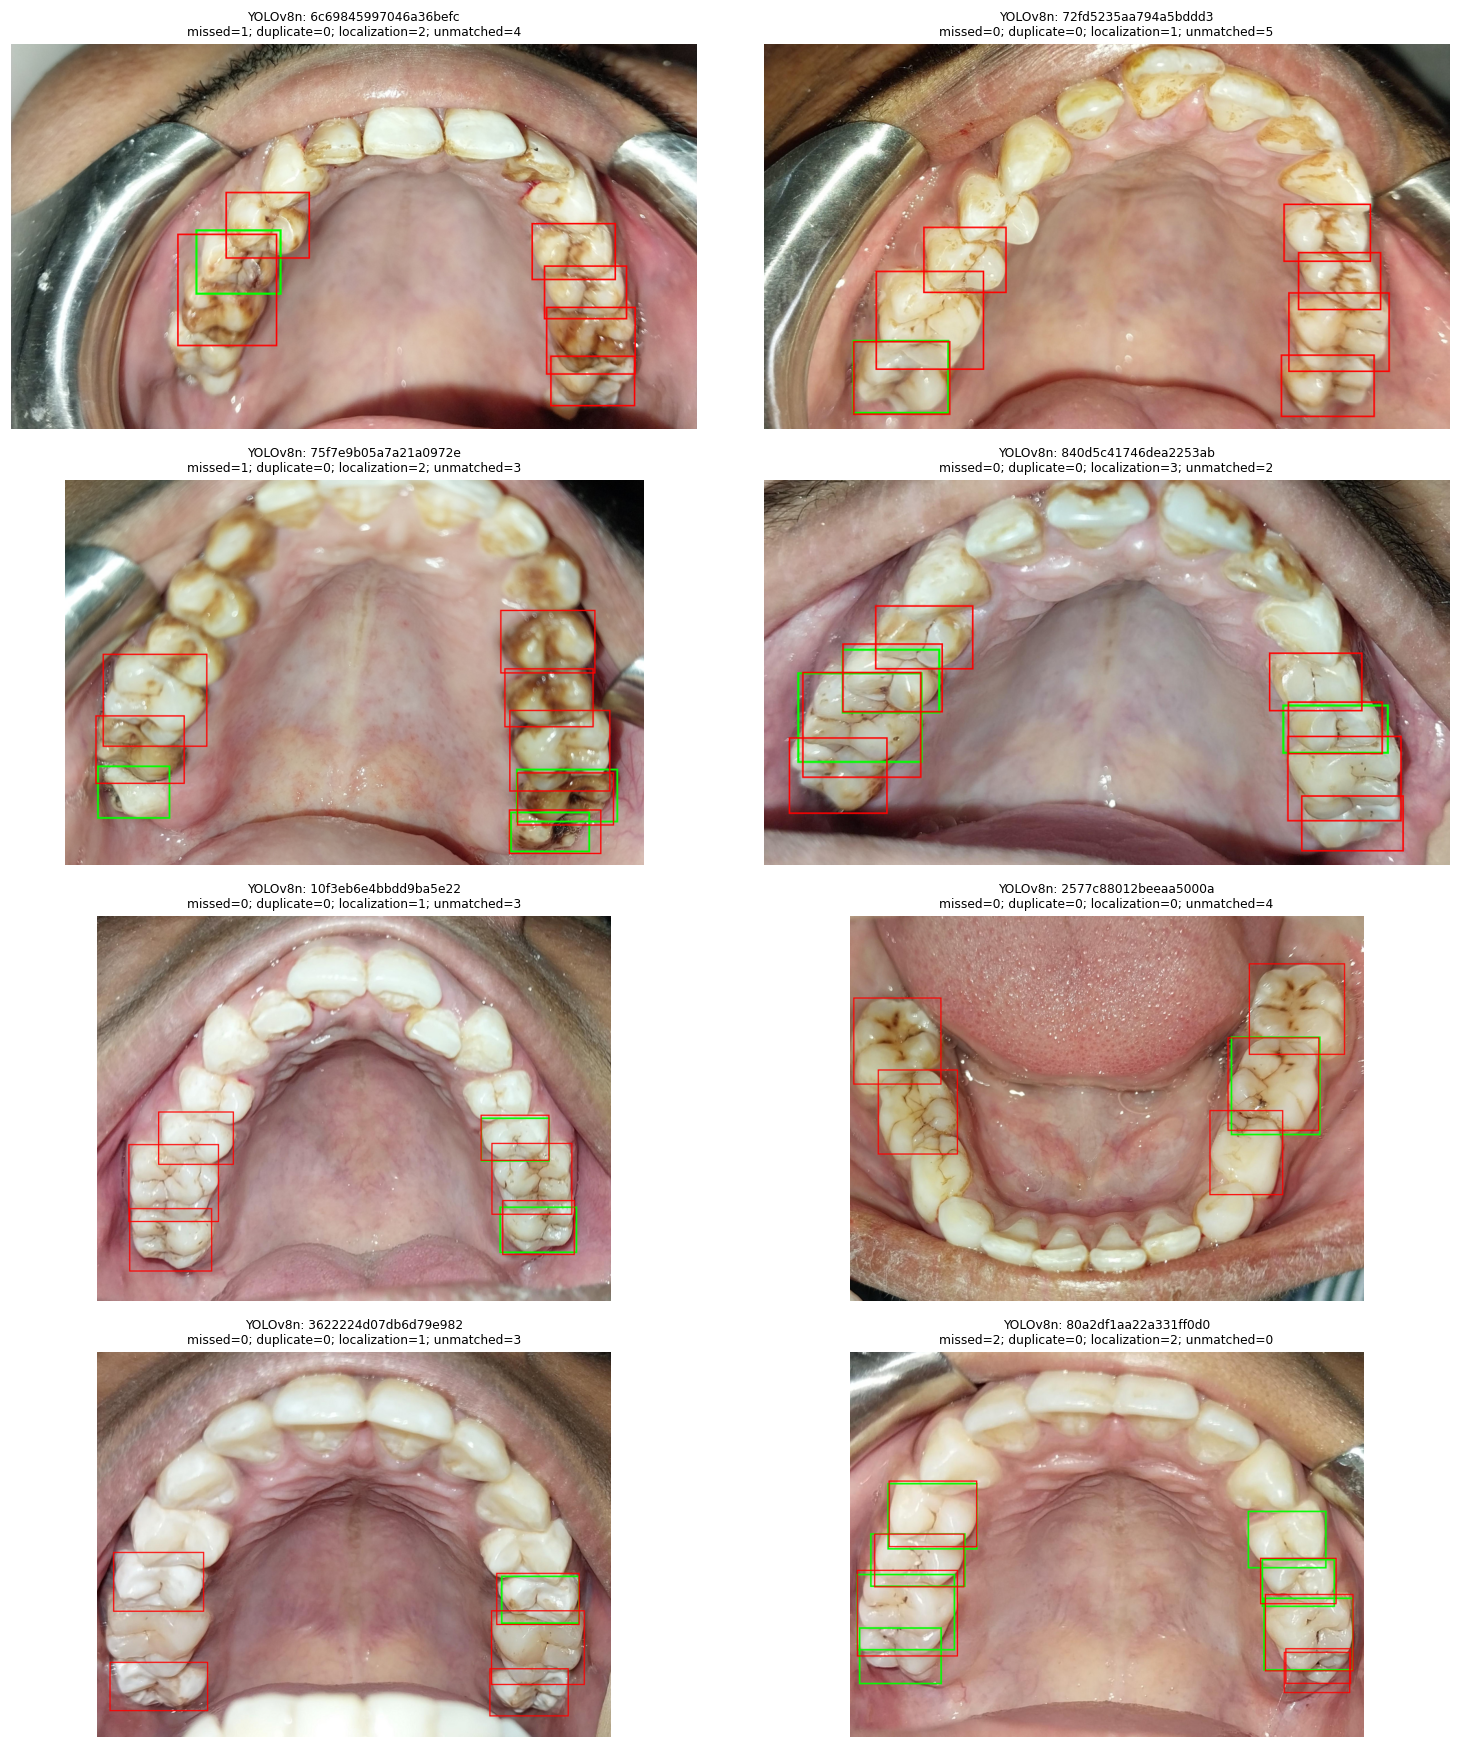

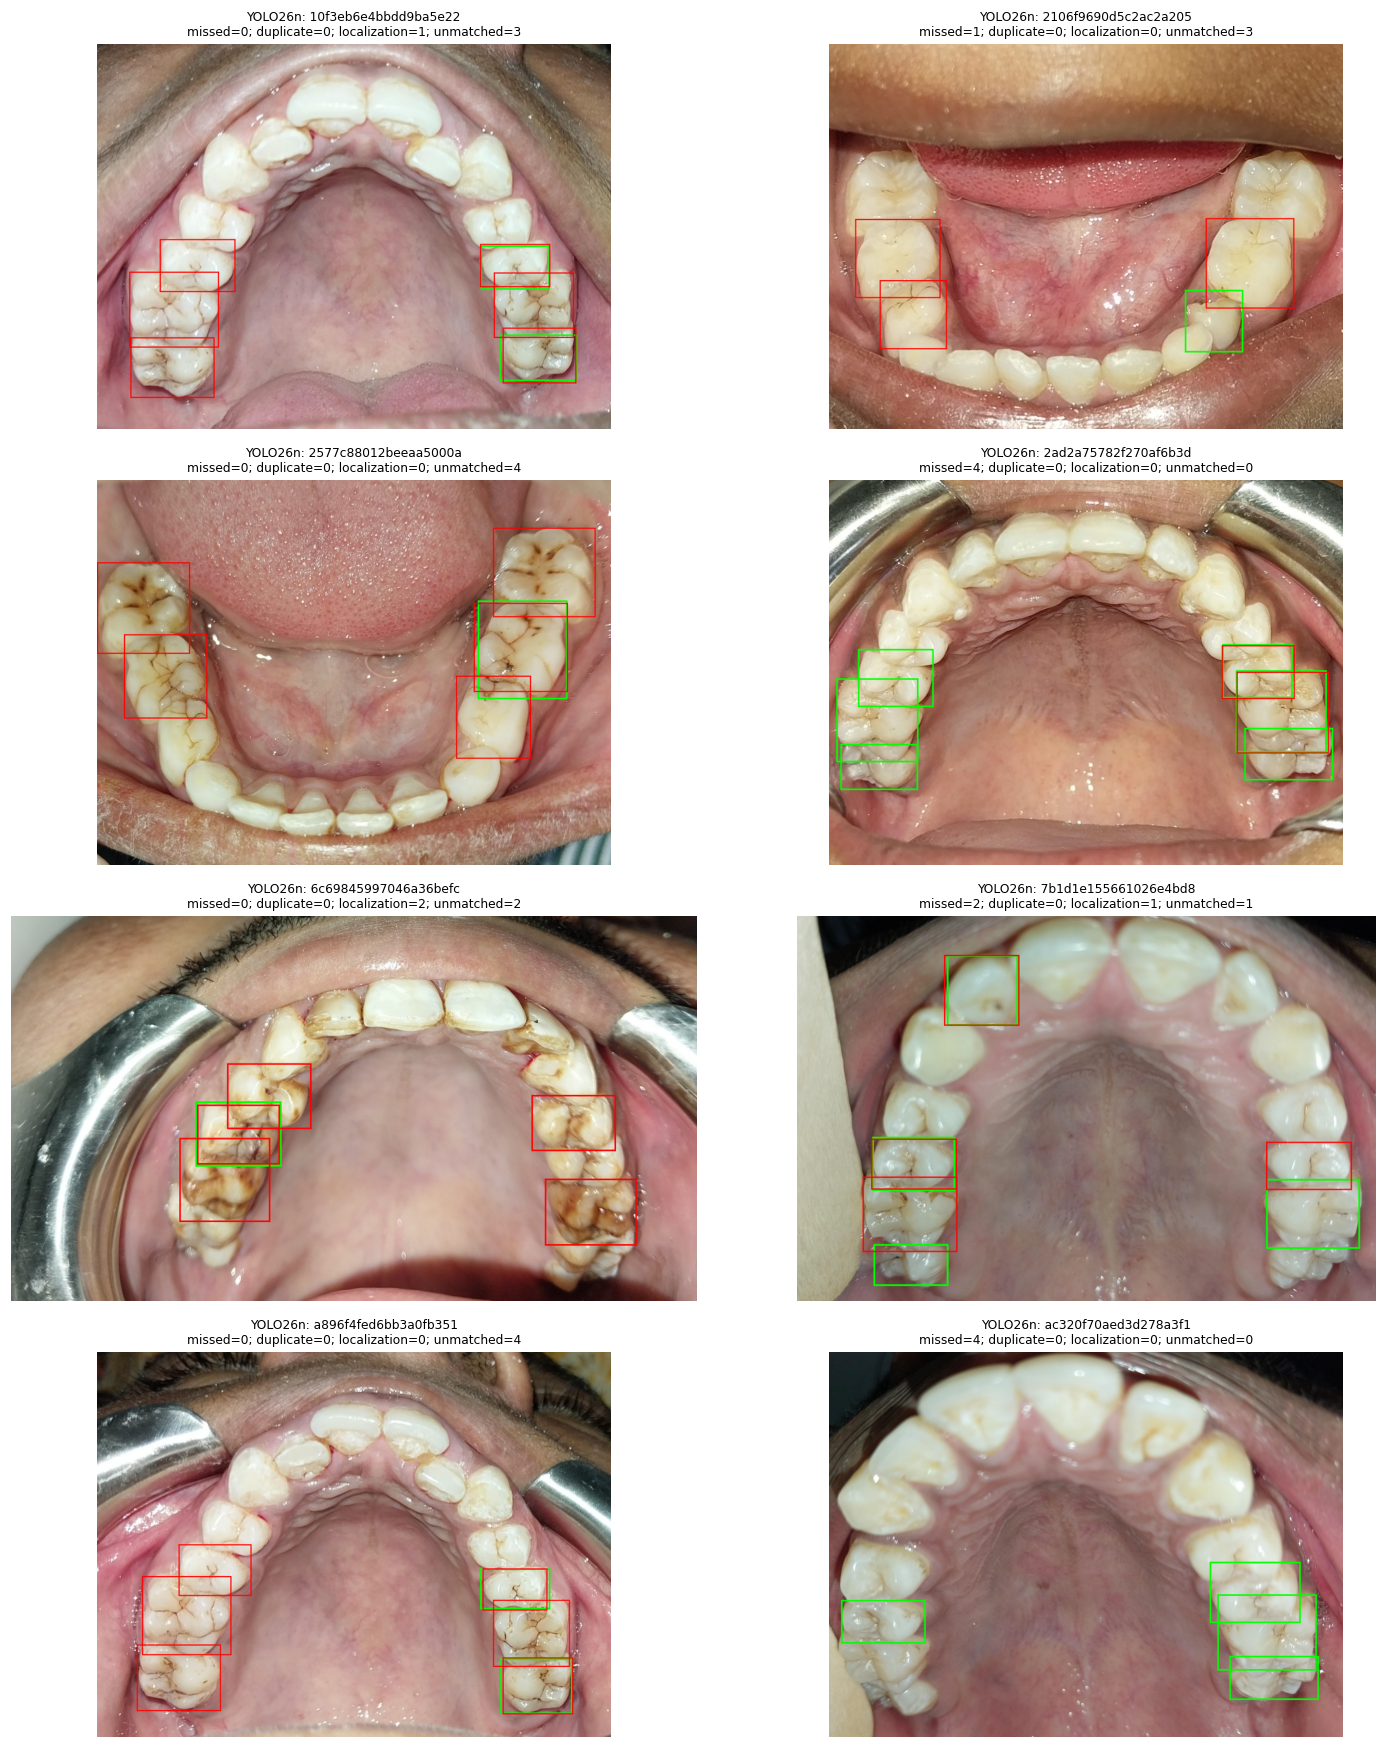

Green = source annotation; red = prediction. These are annotation-relative error examples.


In [7]:
for name in weights:
    failures=images[(images.model==name)&images.variant.eq('clean')].copy()
    failures['error_count']=failures[['missed','duplicate','localization','unmatched']].sum(axis=1)
    selected=failures.sort_values(['error_count','sample_id'],ascending=[False,True]).head(8)
    fig,axes=plt.subplots(4,2,figsize=(14,16))
    for ax,item in zip(axes.flat,selected.itertuples()):
        row=val.set_index('sample_id').loc[item.sample_id]
        with Image.open(ROOT/row.image) as image:
            image=image.convert('RGB');draw=ImageDraw.Draw(image)
            for box in gt[item.sample_id]:draw.rectangle(tuple(box),outline='lime',width=4)
            for d in prediction_cache[(name,'clean')][item.sample_id]:
                x,y,w,h=d['bbox'];draw.rectangle((x,y,x+w,y+h),outline='red',width=3)
            image.thumbnail((1000,700));ax.imshow(image)
        ax.set_title(f'{name}: {item.sample_id}\nmissed={item.missed}; duplicate={item.duplicate}; localization={item.localization}; unmatched={item.unmatched}',fontsize=8);ax.axis('off')
    fig.tight_layout();fig.savefig(OUT/(name+'_full_image_errors.png'));plt.show()
print('Green = source annotation; red = prediction. These are annotation-relative error examples.')

## 8. Robustness, timing and evidence-based scope
Compare fixed synthetic perturbations against the same model's clean performance. Curves and raw detections are saved in each native validation directory. No phone accuracy or clinical usability is established here.

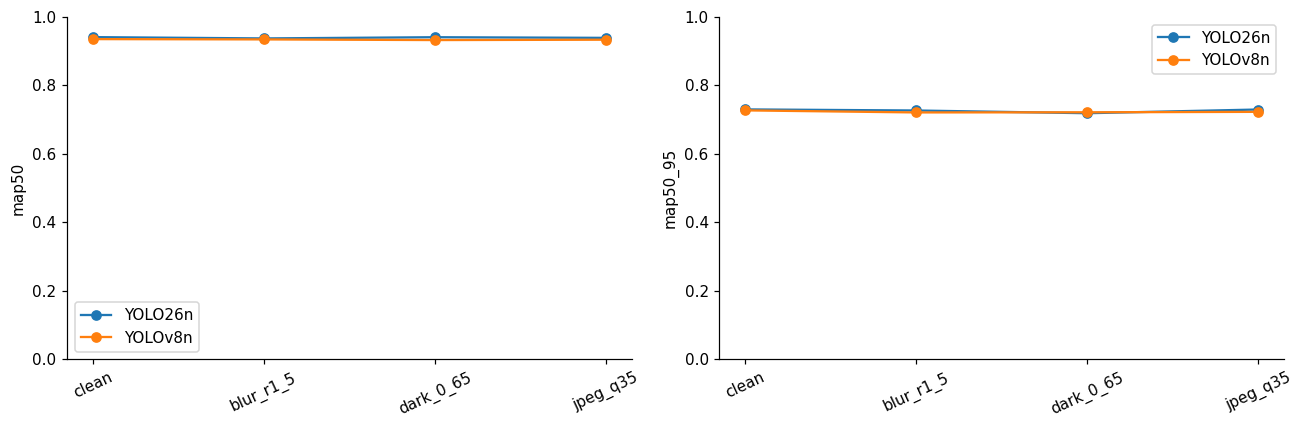

,model,preprocess,inference,loss,postprocess,wall_seconds
0,YOLOv8n,0.602676,26.127917,0.000209,0.394701,30.996544
1,YOLO26n,0.569854,25.084099,0.000149,0.319446,14.278723


Timing includes validator batch/runtime behavior; not per-request phone latency.


**Next decision:** use full-image errors and corruption gaps to specify a realistic capture feasibility check. Keep personal photographs local and report no accuracy without independent reference labels.

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,group in summary.groupby('model'):
    for ax,metric in zip(axes,['map50','map50_95']):
        ax.plot(group.variant,group[metric],marker='o',label=name);ax.set(ylabel=metric,ylim=(0,1))
        ax.tick_params(axis='x',rotation=25);ax.legend()
fig.tight_layout();fig.savefig(OUT/'robustness_comparison.png');plt.show()
runtime=[]
for name in weights:
    item=json.loads((OUT/(name+'_clean')/'audit_receipt.json').read_text())
    runtime.append({'model':name,**item['speed_ms_per_image'],'wall_seconds':item['wall_seconds']})
display(pd.DataFrame(runtime));print('Timing includes validator batch/runtime behavior; not per-request phone latency.')
save_json(OUT/'summary.json',{'protocol':protocol,'validation_images':len(val),'validation_lesions':len(lesions),
                            'test_images_opened':0,'split_sha256':lock['splits_sha256'],
                            'models':list(weights),'runs':len(summary),
                            'limitations':['source-domain validation only','observable groups are not verified patients',
                                           'synthetic corruptions are not external phone images',
                                           'unmatched detections require annotation review']})
display(Markdown('**Next decision:** use full-image errors and corruption gaps to specify a realistic capture feasibility check. '
                 'Keep personal photographs local and report no accuracy without independent reference labels.'))

## 9. Collected evidence and presentation summary

Show native clean-data precision-recall curves next to the operating-point diagnostics. Native AP and fixed-threshold precision/recall answer different questions. CPU re-evaluation is a new inference run; minor differences from historical GPU metrics are retained.

,model,variant,map50,map50_95,wall_seconds
0,YOLOv8n,clean,0.935446,0.727273,30.996544
1,YOLOv8n,blur_r1_5,0.934536,0.721264,18.483587
2,YOLOv8n,dark_0_65,0.932635,0.721714,22.231170
3,YOLOv8n,jpeg_q35,0.933672,0.722987,13.246664
4,YOLO26n,clean,0.941227,0.730115,14.278723
5,YOLO26n,blur_r1_5,0.937436,0.726929,15.916672
6,YOLO26n,dark_0_65,0.940942,0.718983,19.117611
7,YOLO26n,jpeg_q35,0.939082,0.729815,10.969242


**YOLOv8n: clean validation precision-recall curve**

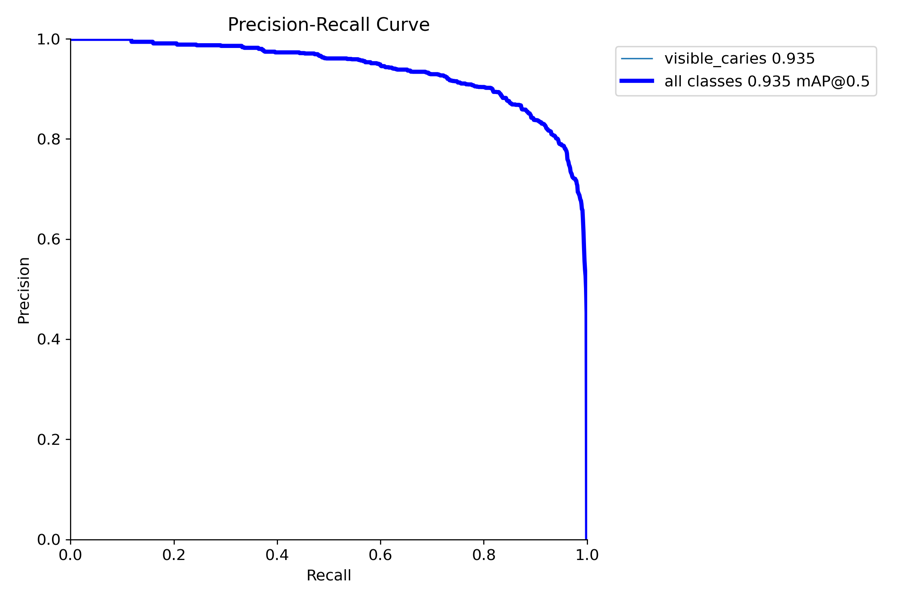

**YOLO26n: clean validation precision-recall curve**

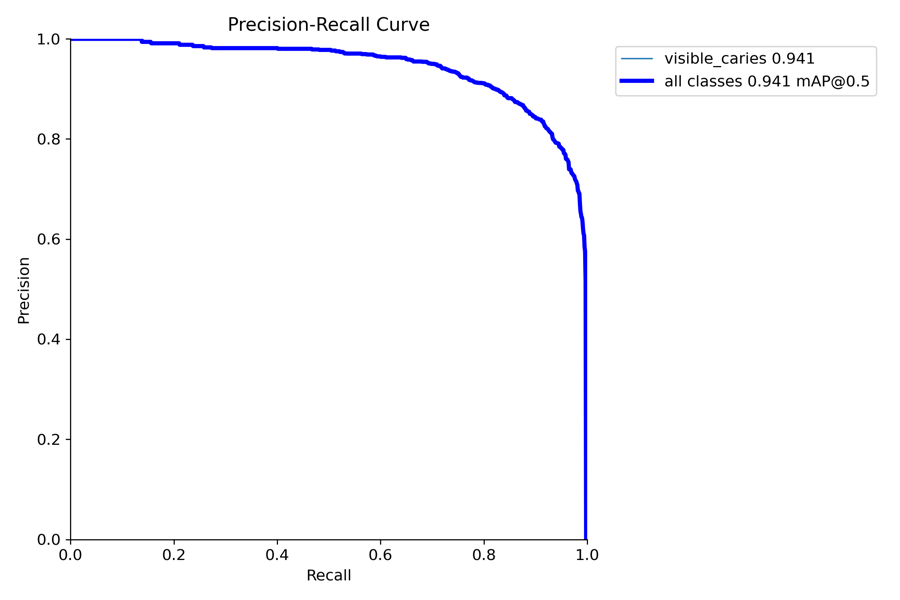

All 327 validation images evaluated for both models across four fixed variants. Test images opened: 0.


In [1]:

from pathlib import Path
import pandas as pd
from PIL import Image
from IPython.display import display, Markdown
out = Path.cwd() / 'docs/reports/post09/caries'
metrics = pd.read_csv(out / 'native_detection_metrics.csv')
display(metrics[['model','variant','map50','map50_95','wall_seconds']])
for name in ['YOLOv8n','YOLO26n']:
    display(Markdown('**' + name + ': clean validation precision-recall curve**'))
    with Image.open(out / (name + '_clean') / 'BoxPR_curve.png') as im:
        preview=im.copy();preview.thumbnail((900,650));display(preview)
print('All 327 validation images evaluated for both models across four fixed variants. Test images opened: 0.')
